# Data-Mining Practice 5
## Myrzakassymov Azizkhan


#### Dataset
##### Adult

Donated on 4/30/1996

Predict whether annual income of an individual exceeds $50K/yr based on census data. Also known as "Census Income" dataset.

##### Dataset Characteristics
Multivariate

##### Subject Area
Social Science

##### Associated Tasks
Classification

##### Feature Type
Categorical, Integer

##### Instances
48842

##### Features
14

##### Additional Information

Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the following conditions: ((AAGE>16) && (AGI>100) && (AFNLWGT>1)&& (HRSWK>0))

Prediction task is to determine whether a person's income is over $50,000 a year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
adult = fetch_ucirepo(id=2) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(adult.data.features)
y = adult.data.targets 
  
display(X)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36,United-States
48838,64,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40,United-States
48839,38,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50,United-States
48840,44,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40,United-States


## Part I. Clustering

### Task 1. K-Means Clustering

1. Select a dataset of your choice with at least two numerical features.
2. Preprocess the data and apply StandardScaler.
3. Implement K-Means with K = 2, 3, and 4.
4. Visualize the clusters using scatter plots.
5. Compare the results and explain how changing K affects clustering.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer

numerical = X.select_dtypes('number').columns.to_list()

num_pipeline = Pipeline( # Imputing and encoding numerical data
    [
        ('imputer', KNNImputer()),
        ('scaler', StandardScaler())
    ]
)

preprocessor = ColumnTransformer( 
    transformers=[
        ('num', num_pipeline, numerical)
    ]
)

Here is preprocessing step with StandardScaler included. If there is any NaN in dataset, it will be imputed with mean of 5 nearest neighbors.

In [4]:
X_preprocessed = preprocessor.fit_transform(X)
display(X_preprocessed)

array([[ 0.02599598, -1.06197924,  1.136512  ,  0.14693247, -0.2171271 ,
        -0.03408696],
       [ 0.82830842, -1.00710388,  1.136512  , -0.14480353, -0.2171271 ,
        -2.21303208],
       [-0.04694151,  0.24603353, -0.41933527, -0.14480353, -0.2171271 ,
        -0.03408696],
       ...,
       [-0.04694151,  1.75486457,  1.136512  , -0.14480353, -0.2171271 ,
         0.77292975],
       [ 0.39068346, -1.00161161,  1.136512  ,  0.58722034, -0.2171271 ,
        -0.03408696],
       [-0.26575399, -0.07117353,  1.136512  , -0.14480353, -0.2171271 ,
         1.57994645]], shape=(48842, 6))

In [5]:
from sklearn.cluster import KMeans

ks = [2, 3, 4]
clustering = {}
for k in ks:
        clustering[k] = KMeans(n_clusters=k).fit(X_preprocessed)

print(clustering)

{2: KMeans(n_clusters=2), 3: KMeans(n_clusters=3), 4: KMeans(n_clusters=4)}


In [6]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=1, cols=len(ks),
    specs=[[{'type': 'scene'}, {'type': 'scene'}, {'type': 'scene'}]],
    subplot_titles=[f'Kmeans (k={k})' for k in ks]
)

for i, k in enumerate(ks, start=1):
    fig.add_trace(
        go.Scatter3d(
            x=X_preprocessed[:, 0],
            y=X_preprocessed[:, 1],
            z=X_preprocessed[:, 2],
            mode='markers',
            marker=dict(
                size=5,
                color=clustering[k].labels_,
                opacity=0.7,
            ),
            name=f'K-Mean Clusters (k={k})',
            showlegend=False,
        ),
        row=1, col=i
    )
    fig.add_trace(
        go.Scatter3d(
            x=clustering[k].cluster_centers_[:, 0],
            y=clustering[k].cluster_centers_[:, 1],
            z=clustering[k].cluster_centers_[:, 2],
            mode='markers',
            marker=dict(
                size=10,
                color='red',
                symbol='x'
            ),
            showlegend=(i==1)
        ),
        row=1, col=i
    )

fig.update_layout(
    title_text="KMeans in 3D",
    height=600,
    width=1100
)

fig.show()

#### How does changing K affects clustering?
KMeans makes clusters on base of some distance, K is number of clusters. It can affect some certain variable (or variables), mean values of which changes from cluster to cluster; coming to interpretability based on various criteria.

### Task 2. Finding the Optimal Number of Clusters

1. Use the dataset from Task 1.
2. Apply the Elbow Method for K = 1–10.
3. Calculate Silhouette Scores for K = 2–10.
4. Visualize the results and determine the optimal number of clusters.
5. Explain whether both methods suggest the same K.

In [7]:
print(clustering[4].labels_)

[0 2 1 ... 0 0 0]


In [8]:
# Elbow method with Inertia and Silhouette score
from sklearn.metrics import silhouette_score
K = range(1, 11)
mapping = {}
inertias = []
silhouette = []

for k in K:
    kmeanmodel = KMeans(n_clusters=k).fit(X_preprocessed)

    inertias.append(kmeanmodel.inertia_)
    mapping[k] = inertias[-1]

    if k > 1:
        score = silhouette_score(X_preprocessed, kmeanmodel.labels_)
        silhouette.append(score)
    else:
        silhouette.append(None)

In [9]:
print(silhouette)

[None, 0.1613575432028847, 0.18845122982527526, 0.2026905934352804, 0.21981719786643608, 0.2295703525570637, 0.23405962564210672, 0.24088624604726921, 0.23499122267976058, 0.23792510474380607]


[293051.99999999953, 255326.41235698154, 211628.0791387288, 166893.70567276442, 142581.31318927452, 123883.37581054276, 112651.68784404022, 102807.89747151041, 97817.04049633893, 91563.26314724093]


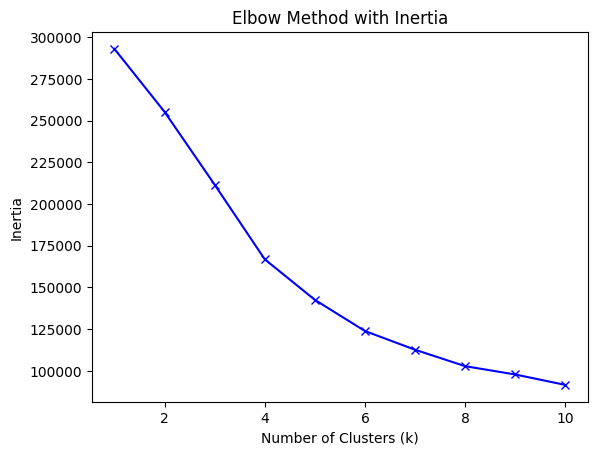

In [10]:
print(inertias)

plt.plot(K, inertias, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method with Inertia')
plt.show()

In Elbow method using inertia, a point that can be identified as elbow is 5, because after this value of K, as K changes, rate of change in Inertia becomes very slow compared to K < 5.

[None, 0.1613575432028847, 0.18845122982527526, 0.2026905934352804, 0.21981719786643608, 0.2295703525570637, 0.23405962564210672, 0.24088624604726921, 0.23499122267976058, 0.23792510474380607]


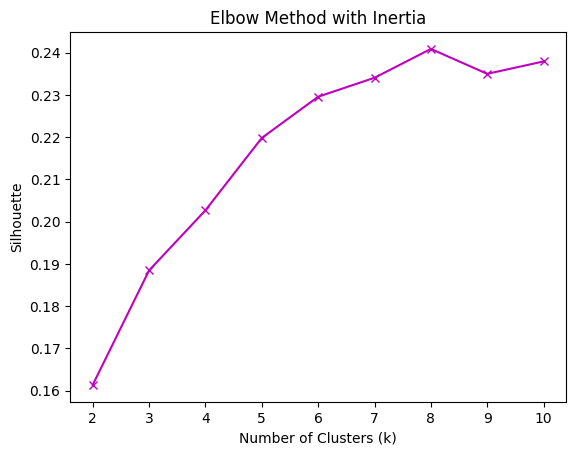

In [ ]:
print (silhouette)

plt.plot(K, silhouette, 'mx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette')
plt.title('Clusters vs Silhouette')
plt.show()

According to silhouette, appropriate number of clusters is 8. Silhouette is more accurate way to choose number of clusters because it does calculations for every point in space of dataset.

In some way, both methods suggest same K, at least in direction.

### Task 3. Hierarchical Clustering

1. Select a numerical dataset and scale its features.
2. Apply Agglomerative Clustering using Ward, Complete, and Average linkage.
3. Generate a dendrogram.
4. Experiment with different numbers of clusters.
5. Compare and visualize the results.

In [ ]:
from scipy.cluster import hierarchy
# Sampling
sample_size = min(5000, X_preprocessed.shape[0])
indices = np.random.choice(X_preprocessed.shape[0], sample_size, replace=True)
X_sample = X_preprocessed[indices]

# Clustering
k = 2

clustering = {
    'Ward' : hierarchy.linkage(X_sample, method='ward', ),
    'Complete' : hierarchy.linkage(X_sample, method='complete'),
    'Average' : hierarchy.linkage(X_sample, method='average', )
}


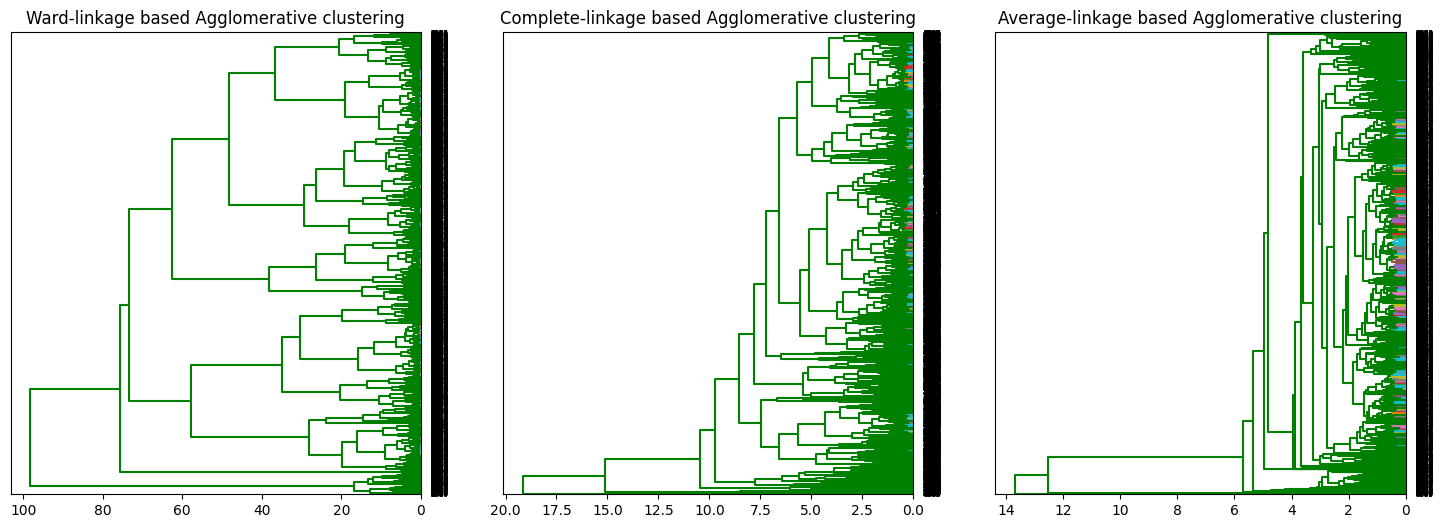

In [95]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6), dpi=100)

for i, linkage in zip(ax, clustering):
    hierarchy.dendrogram(
        clustering[linkage], above_threshold_color='green', color_threshold=.5, orientation='left', ax=i
    )
    i.set_title(f'{linkage}-linkage based Agglomerative clustering')

plt.show()

### Task 4. DBSCAN Clustering
1. Select a dataset with at least two numerical features.
2. Apply feature scaling.
3. Implement DBSCAN with different eps and min_samples values.
4. Visualize the clusters and identify outliers (noise).
5. Compare DBSCAN results with K-Means

In [122]:
from sklearn.cluster import DBSCAN
es = [0.2, 0.7, 1, 2]
clustering = {}
for e in es:
    clustering[e] = DBSCAN(eps=e)
    clustering[e].fit(X_sample)


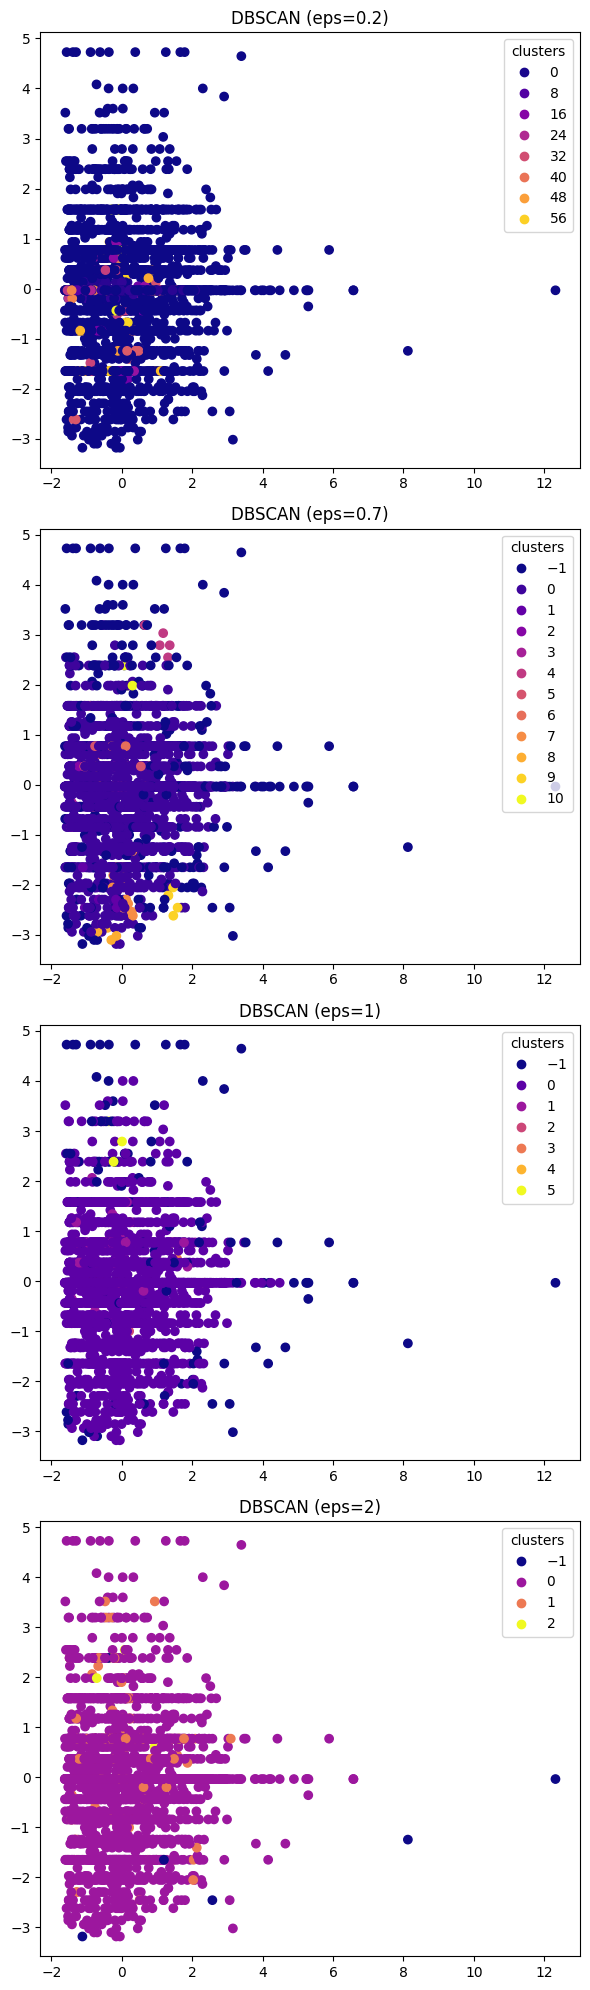

In [126]:
fig, axes = plt.subplots(ncols=1, nrows=len(es), figsize=(6, 20), dpi=100)

for ax, e in zip(axes, es):
    labels = clustering[e].labels_

    scatter = ax.scatter(
        x=X_sample[:, 1],
        y=X_sample[:, 5],
        c=labels,
        cmap='plasma'
    )

    ax.set_title(f'DBSCAN (eps={e})')
    ax.legend(*scatter.legend_elements(), title='clusters')
    

plt.tight_layout()
plt.show()


As one can notice, number of clusters decreasing as eps is increasing. It is because bound of distance between two points to be considered in neighborhood of each other is increased, thus, less clusters is created.

## Part II. Ensemble Learning: Bagging and Boosting

### Task 5. Bagging – Random Forest

1. Select a classification dataset of your choice.
2. Split the data into training (80%) and testing (20%) sets.
3. Train a Decision Tree as a baseline model.
4. Implement Random Forest with 10, 50, and 100 estimators.
5. Compare models using Accuracy, Precision, Recall, and F1-score.
6. Explain how bagging improves model performance.

### Task 6. Boosting – AdaBoost and Gradient Boosting

1. Use the same dataset from Task 5.
2. Implement AdaBoost and Gradient Boosting.
3. Experiment with different n_estimators, learning_rate, and max_depth values.
4. Evaluate the models using Accuracy, Precision, Recall, and F1-score.
5. Identify the best hyperparameter combination and explain the results.


### Task 7. Comparing Bagging and Boosting

1. Train four models on the same dataset:
 - Decision Tree
 - Random Forest
 - Gradient Boosting
2. Apply GridSearchCV with 5-fold cross-validation.
3. Find the optimal hyperparameters for each model.
4. Compare their performance using a table and bar chart.
5. Identify the best model and explain why it outperformed the others.